In [41]:
import requests
import json
import time
import pandas as pd
import hashlib

from pathlib import Path
from datetime import datetime, timezone

print("Library tersimpan bro")

Library tersimpan bro


In [42]:
folders = [
    "data/raw",
    "data/interim",
    "docs",
    "notebooks",
    "reports"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Semua folder berhasil dibuat!")


Semua folder berhasil dibuat!


In [43]:
URL = "https://overpass-api.de/api/interpreter"

HEADERS = {
    "User-Agent": "INSTIKI-BIFP243-Praktikum/1.0"
}

QUERY = """
[out:json][timeout:90];

area["name"="Kintamani"]
["boundary"="administrative"]
["admin_level"="6"]->.kec;

nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"]
(area.kec);

out center tags;
"""

print("Query berhasil disiapkan!")

Query berhasil disiapkan!


In [44]:
def ambil_overpass(query, maks_percobaan=4, jeda=5):

    for percobaan in range(1, maks_percobaan + 1):

        try:
            response = requests.post(
                URL,
                data={"data": query},
                headers=HEADERS,
                timeout=120
            )

            if response.status_code == 200:
                return response.json()

            print(
                f"Percobaan {percobaan}: "
                f"Status {response.status_code}"
            )

        except (requests.Timeout, requests.ConnectionError) as error:
            print("Terjadi error:", error)

        if percobaan < maks_percobaan:
            print(f"Mencoba kembali dalam {jeda} detik...")
            time.sleep(jeda)
            jeda *= 2

    raise RuntimeError("Gagal mengambil data dari Overpass API")

print("Fungsi akuisisi berhasil dibuat!")

Fungsi akuisisi berhasil dibuat!


In [45]:
data = ambil_overpass(QUERY)

print("AKUISISI BERHASIL!")
print("Jumlah seluruh elemen:", len(data["elements"]))


Percobaan 1: Status 502
Mencoba kembali dalam 5 detik...
AKUISISI BERHASIL!
Jumlah seluruh elemen: 32


In [46]:
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

raw_path = Path(
    f"data/raw/osm_akomodasi_kintamani_{stamp}.json"
)

raw_path.write_text(
    json.dumps(data, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("File JSON berhasil disimpan!")
print("Lokasi:", raw_path)

File JSON berhasil disimpan!
Lokasi: data/raw/osm_akomodasi_kintamani_20261112_070743.json


In [47]:
data = ambil_overpass(QUERY)

print("AKUISISI BERHASIL!")
print("Jumlah seluruh elemen:", len(data["elements"]))

AKUISISI BERHASIL!
Jumlah seluruh elemen: 32


In [48]:
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

raw_path = Path(
    f"data/raw/osm_akomodasi_kintamani_{stamp}.json"
)

raw_path.write_text(
    json.dumps(data, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("File JSON berhasil disimpan!")
print("Lokasi:", raw_path)

File JSON berhasil disimpan!
Lokasi: data/raw/osm_akomodasi_kintamani_20261112_070807.json


In [49]:
def ratakan(elements):
    baris = []

    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)

        baris.append({
            "osm_type": e["type"],
            "osm_id": e["id"],
            "nama": tg.get("name"),
            "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"),
            "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"),
            "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}"
        })

    return pd.DataFrame(baris)

df = ratakan(data["elements"])

print("Data berhasil diubah menjadi tabel!")
print("Jumlah baris:", len(df))

Data berhasil diubah menjadi tabel!
Jumlah baris: 32


In [50]:
KOLOM = ["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "desa", "bintang", "jumlah_kamar", "website", "url_osm"]

# Mendefinisikan INTERIM_DIR yang belum terdefinisi
from pathlib import Path
INTERIM_DIR = Path("data/interim")

# Mengganti 'akomodasi' menjadi 'df'
df[KOLOM].to_csv(INTERIM_DIR / "akomodasi_kintamani.csv", index=False, encoding="utf-8")
print("Disimpan:", INTERIM_DIR / "akomodasi_kintamani.csv", "-", len(df), "baris")

print("\nJumlah per jenis:")
print(df["jenis"].value_counts())
print("\nJumlah per desa:")
print(df["desa"].fillna("(tanpa tag desa)").value_counts())

Disimpan: data/interim/akomodasi_kintamani.csv - 32 baris

Jumlah per jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Jumlah per desa:
desa
(tanpa tag desa)    32
Name: count, dtype: int64


In [51]:
display(df)

,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,None,None,None,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,None,None,None,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,None,None,None,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,None,None,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,None,None,None,https://www.openstreetmap.org/node/5175562421


In [52]:
csv_path = Path("data/interim/akomodasi_kintamani.csv")

df.to_csv(csv_path, index=False, encoding="utf-8-sig")

print("File CSV berhasil disimpan!")
print("Lokasi:", csv_path)

File CSV berhasil disimpan!
Lokasi: data/interim/akomodasi_kintamani.csv


In [53]:
print("Ukuran data:", df.shape)
print("Nama kolom:")
print(df.columns.tolist())

Ukuran data: (32, 11)
Nama kolom:
['osm_type', 'osm_id', 'nama', 'jenis', 'lat', 'lon', 'desa', 'bintang', 'jumlah_kamar', 'website', 'url_osm']


In [54]:
duplikat = df.duplicated(
    subset=["osm_type", "osm_id"]
).sum()

print("Jumlah data duplikat:", duplikat)

Jumlah data duplikat: 0


In [55]:
nama_kosong = df["nama"].isna().sum()

print("Jumlah data tanpa nama:", nama_kosong)

Jumlah data tanpa nama: 1


In [56]:
print("Jumlah data kosong setiap kolom:")
display(df.isnull().sum())

Jumlah data kosong setiap kolom:


,0
osm_type,0
osm_id,0
nama,1
jenis,0
lat,0
lon,0
desa,32
bintang,31
jumlah_kamar,30
website,30


In [57]:
display(df[df["nama"].isna()])

,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
31,way,1181397894,None,motel,-8.223372,115.254582,None,None,None,None,https://www.openstreetmap.org/way/1181397894


In [58]:
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

raw_path = Path(
    f"data/raw/osm_akomodasi_kintamani_{stamp}.json"
)

raw_path.write_text(
    json.dumps(data, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("File JSON berhasil disimpan!")
print("Lokasi:", raw_path)

File JSON berhasil disimpan!
Lokasi: data/raw/osm_akomodasi_kintamani_20261112_070808.json


In [59]:
def ratakan(elements):
    baris = []

    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)

        baris.append({
            "osm_type": e["type"],
            "osm_id": e["id"],
            "nama": tg.get("name"),
            "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"),
            "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"),
            "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}"
        })

    return pd.DataFrame(baris)


df = ratakan(data["elements"])

print("Data berhasil diubah menjadi tabel!")
print("Jumlah baris:", len(df))

df.head()

Data berhasil diubah menjadi tabel!
Jumlah baris: 32


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696


In [60]:
print("Jumlah seluruh data:", len(df))

duplikat = df.duplicated(
    subset=["osm_type", "osm_id"]
).sum()

print("Jumlah data duplikat:", duplikat)

tanpa_nama = df["nama"].isna().sum()

print("Jumlah data tanpa nama:", tanpa_nama)

print("\nJumlah data kosong setiap kolom:")
print(df.isna().sum())

Jumlah seluruh data: 32
Jumlah data duplikat: 0
Jumlah data tanpa nama: 1

Jumlah data kosong setiap kolom:
osm_type         0
osm_id           0
nama             1
jenis            0
lat              0
lon              0
desa            32
bintang         31
jumlah_kamar    30
website         30
url_osm          0
dtype: int64


In [61]:
print("Rentang Latitude:")
print(df["lat"].min(), "sampai", df["lat"].max())

print("\nRentang Longitude:")
print(df["lon"].min(), "sampai", df["lon"].max())

print("\nData dengan koordinat kosong:")
print(df[["lat", "lon"]].isna().sum())

Rentang Latitude:
-8.2837958 sampai -8.2189435

Rentang Longitude:
115.2545822 sampai 115.4129261

Data dengan koordinat kosong:
lat    0
lon    0
dtype: int64


In [62]:
!pip install folium

In [63]:
import folium
import pandas as pd

tengah_lat = df["lat"].mean()
tengah_lon = df["lon"].mean()

peta = folium.Map(
    location=[tengah_lat, tengah_lon],
    zoom_start=12,
    tiles="CartoDB positron"
)

for _, baris in df.iterrows():
    nama = baris["nama"] if pd.notna(baris["nama"]) else "Tanpa nama"

    folium.Marker(
        location=[baris["lat"], baris["lon"]],
        popup=f"{nama} - {baris['jenis']}",
        tooltip=nama
    ).add_to(peta)

peta

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [64]:
jumlah_jenis = df["jenis"].value_counts()

print("Jumlah Akomodasi Berdasarkan Jenis:")
print(jumlah_jenis)

Jumlah Akomodasi Berdasarkan Jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64


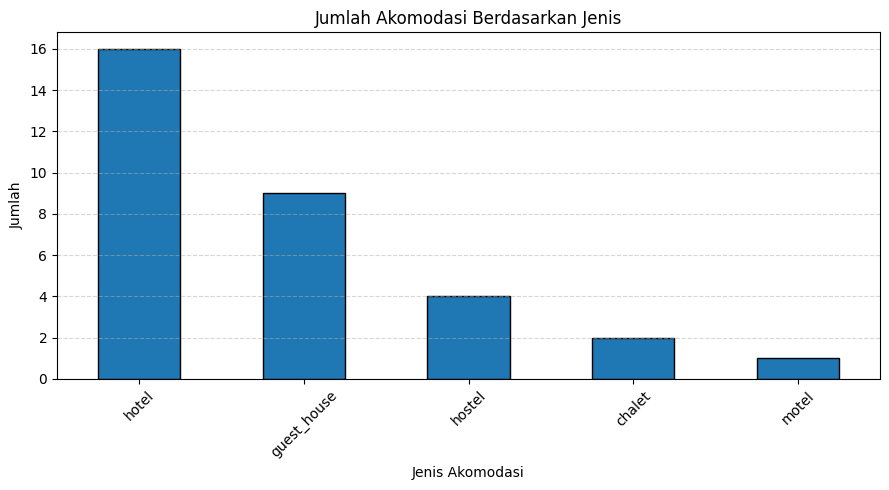

In [65]:
import matplotlib.pyplot as plt

jumlah_jenis = df["jenis"].value_counts()

plt.figure(figsize=(9, 5))

jumlah_jenis.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Jumlah Akomodasi Berdasarkan Jenis")
plt.xlabel("Jenis Akomodasi")
plt.ylabel("Jumlah")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [66]:
ringkasan = df.groupby("jenis").agg(
    jumlah_data=("osm_id", "count"),
    jumlah_nama=("nama", "count"),
    jumlah_website=("website", "count")
).reset_index()

ringkasan

,jenis,jumlah_data,jumlah_nama,jumlah_website
0,chalet,2,2,0
1,guest_house,9,9,0
2,hostel,4,4,0
3,hotel,16,16,2
4,motel,1,0,0


In [67]:
data_bps = pd.DataFrame({
    "jenis": ["Hotel", "Penginapan"],
    "jumlah": [19, 39],
    "tahun": [2023, 2023]
})

data_bps

,jenis,jumlah,tahun
0,Hotel,19,2023
1,Penginapan,39,2023


In [68]:
data_bps.to_csv(
    "docs/data_bps_kintamani.csv",
    index=False
)

print("Data BPS berhasil disimpan!")

Data BPS berhasil disimpan!


In [69]:
total_osm = len(df)
hotel_bps = 19
penginapan_bps = 39

total_bps = hotel_bps + penginapan_bps

persentase = (total_osm / total_bps) * 100

perbandingan = pd.DataFrame({
    "Sumber": ["OpenStreetMap", "BPS"],
    "Jumlah Akomodasi": [total_osm, total_bps],
    "Tahun": ["2026", "2023"]
})

print(perbandingan)
print(f"\nPersentase perbandingan: {persentase:.2}%")

perbandingan.to_csv(
    "docs/perbandingan_bps.csv",
    index=False
)

          Sumber  Jumlah Akomodasi Tahun
0  OpenStreetMap                32  2026
1            BPS                58  2023

Persentase perbandingan: 5.5e+01%


In [70]:
sampel = df.sample(n=10, random_state=42)

sampel[[
    "osm_type",
    "osm_id",
    "nama",
    "jenis",
    "lat",
    "lon",
    "website",
    "url_osm"
]]

,osm_type,osm_id,nama,jenis,lat,lon,website,url_osm
29,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,None,https://www.openstreetmap.org/node/13068182153
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,None,https://www.openstreetmap.org/node/6451134585
24,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,None,https://www.openstreetmap.org/node/9769685089
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,None,https://www.openstreetmap.org/node/7058054537
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,https://www.openstreetmap.org/node/5175562421
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,None,https://www.openstreetmap.org/node/13284479326
25,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,None,https://www.openstreetmap.org/node/9778735917
12,node,5479746121,Hut,chalet,-8.242693,115.387587,None,https://www.openstreetmap.org/node/5479746121
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907


In [71]:
sampel_verifikasi = sampel.copy()

sampel_verifikasi["status_verifikasi"] = ""
sampel_verifikasi["sumber_verifikasi"] = ""
sampel_verifikasi["catatan"] = ""

sampel_verifikasi.to_csv(
    "docs/verifikasi_manual_10_sampel.csv",
    index=False
)

print("10 sampel berhasil disimpan!")

10 sampel berhasil disimpan!


In [72]:
hasil_verifikasi = [
    "Sesuai",
    "Sesuai",
    "Sesuai",
    "Sesuai",
    "Jenis berbeda",
    "Perlu pemeriksaan objek",
    "Sesuai",
    "Sesuai",
    "Tidak ditemukan",
    "Sesuai"
]

catatan_verifikasi = [
    "-",
    "-",
    "-",
    "-",
    "Jenis akomodasi tidak sesuai",
    "Nama objek menunjukkan titik pintu masuk hostel",
    "-",
    "-",
    "Tidak berhasil ditemukan",
    "-"
]

sampel_verifikasi["status_verifikasi"] = hasil_verifikasi
sampel_verifikasi["catatan"] = catatan_verifikasi

sampel_verifikasi.to_csv(
    "docs/verifikasi_manual_10_sampel.csv",
    index=False
)

print("Hasil verifikasi berhasil disimpan!")

Hasil verifikasi berhasil disimpan!


In [73]:
import json
from datetime import datetime, timezone
import hashlib
import glob
import os

file_raw = glob.glob("data/raw/*.json")[0]

with open(file_raw, "rb") as f:
    isi_file = f.read()

hash_md5 = hashlib.md5(isi_file).hexdigest()

provenance = {
    "sumber_data": "OpenStreetMap",
    "endpoint": "https://overpass-api.de/api/interpreter",
    "waktu_akuisisi_utc": datetime.now(timezone.utc).isoformat(),
    "jumlah_data": 32,
    "file_raw": file_raw,
    "md5": hash_md5,
    "lisensi": "Open Database License (ODbL)",
    "atribusi": "© OpenStreetMap contributors",
    "metode": "Overpass API"
}

with open("docs/provenance.json", "w") as f:
    json.dump(provenance, f, indent=4)

print("File provenance.json berhasil dibuat!")
print(json.dumps(provenance, indent=4))

File provenance.json berhasil dibuat!
{
    "sumber_data": "OpenStreetMap",
    "endpoint": "https://overpass-api.de/api/interpreter",
    "waktu_akuisisi_utc": "2026-11-12T07:08:12.621729+00:00",
    "jumlah_data": 32,
    "file_raw": "data/raw/osm_akomodasi_kintamani_20261112_070556.json",
    "md5": "2bf133ba5df6092961fa1f97dd1059d0",
    "lisensi": "Open Database License (ODbL)",
    "atribusi": "\u00a9 OpenStreetMap contributors",
    "metode": "Overpass API"
}


In [74]:
import pandas as pd

data_dictionary = pd.DataFrame({
    "Nama Kolom": [
        "osm_type",
        "osm_id",
        "nama",
        "jenis",
        "lat",
        "lon",
        "desa",
        "bintang",
        "jumlah_kamar",
        "website",
        "url_osm"
    ],
    "Keterangan": [
        "Jenis objek OpenStreetMap",
        "ID unik objek OpenStreetMap",
        "Nama akomodasi",
        "Kategori akomodasi",
        "Koordinat lintang",
        "Koordinat bujur",
        "Nama desa akomodasi",
        "Jumlah bintang akomodasi",
        "Jumlah kamar akomodasi",
        "Alamat website akomodasi",
        "Tautan objek OpenStreetMap"
    ],
    "Tipe Data": [
        "Teks", "Integer", "Teks", "Teks",
        "Float", "Float", "Teks", "Teks",
        "Teks", "Teks", "Teks"
    ]
})

data_dictionary.to_csv(
    "docs/data_dictionary.csv",
    index=False
)

print(data_dictionary)
print("\nFile data_dictionary.csv berhasil dibuat!")

      Nama Kolom                   Keterangan Tipe Data
0       osm_type    Jenis objek OpenStreetMap      Teks
1         osm_id  ID unik objek OpenStreetMap   Integer
2           nama               Nama akomodasi      Teks
3          jenis           Kategori akomodasi      Teks
4            lat            Koordinat lintang     Float
5            lon              Koordinat bujur     Float
6           desa          Nama desa akomodasi      Teks
7        bintang     Jumlah bintang akomodasi      Teks
8   jumlah_kamar       Jumlah kamar akomodasi      Teks
9        website     Alamat website akomodasi      Teks
10       url_osm   Tautan objek OpenStreetMap      Teks

File data_dictionary.csv berhasil dibuat!


In [75]:
data_etika = pd.DataFrame({
    "Aspek Etika": [
        "Sumber data jelas",
        "Menggunakan OpenStreetMap",
        "Menggunakan Overpass API",
        "Tidak mengambil nomor telepon",
        "Tidak mengambil email",
        "Tidak mengambil akun media sosial",
        "Tidak menggunakan situs pemesanan terlarang",
        "Menyimpan data mentah JSON",
        "Mencantumkan atribusi OpenStreetMap",
        "Mematuhi lisensi ODbL"
    ],
    "Status": [
        "Ya", "Ya", "Ya", "Ya", "Ya",
        "Ya", "Ya", "Ya", "Ya", "Ya"
    ]
})

data_etika.to_csv(
    "docs/data_ethics_checklist.csv",
    index=False
)

print(data_etika)
print("\nChecklist etika berhasil dibuat!")

                                   Aspek Etika Status
0                            Sumber data jelas     Ya
1                    Menggunakan OpenStreetMap     Ya
2                     Menggunakan Overpass API     Ya
3                Tidak mengambil nomor telepon     Ya
4                        Tidak mengambil email     Ya
5            Tidak mengambil akun media sosial     Ya
6  Tidak menggunakan situs pemesanan terlarang     Ya
7                   Menyimpan data mentah JSON     Ya
8          Mencantumkan atribusi OpenStreetMap     Ya
9                        Mematuhi lisensi ODbL     Ya

Checklist etika berhasil dibuat!


In [76]:
ringkasan_jenis = df["jenis"].value_counts().reset_index()

ringkasan_jenis.columns = [
    "Jenis Akomodasi",
    "Jumlah"
]

print(ringkasan_jenis)

  Jenis Akomodasi  Jumlah
0           hotel      16
1     guest_house       9
2          hostel       4
3          chalet       2
4           motel       1


In [82]:
!git config --global user.name "igustingurahdwiandikaputra-code"
!git config --global user.email "email-github-anda@example.com"

In [83]:
!git config --list

user.name=igustingurahdwiandikaputra-code
user.email=email-github-anda@example.com


In [84]:
%cd AKOMODASI_DWI

[Errno 2] No such file or directory: 'AKOMODASI_DWI'
/content


In [85]:
!git pull origin main

fatal: not a git repository (or any of the parent directories): .git


In [87]:
# 1. Pastikan Anda berada di dalam folder repositori
%cd /content/AKOMODASI_DWI

# 2. Salin folder-folder tersebut dari direktori asal Anda ke folder repositori saat ini
# (Sesuaikan path sumber jika folder tersebut berada di /content/ atau direktori lain)
!cp -r /content/data .
!cp -r /content/docs .
!cp -r /content/notebooks .
!cp -r /content/reports .

# 3. Masukkan semua perubahan ke Git
!git add .

# 4. Buat pesan commit
!git commit -m "Menambahkan folder data, docs, notebooks, dan reports"

# 5. Kirim ke GitHub
!git push origin main

[Errno 2] No such file or directory: '/content/AKOMODASI_DWI'
/content
cp: '/content/data' and './data' are the same file
cp: '/content/docs' and './docs' are the same file
cp: '/content/notebooks' and './notebooks' are the same file
cp: '/content/reports' and './reports' are the same file
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [88]:
%cd /content
!ls

/content
data  docs  notebooks  reports	sample_data


In [89]:
!ls notebooks docs reports data/raw data/interim
!ls README.md

data/interim:
akomodasi_kintamani.csv

data/raw:
osm_akomodasi_kintamani_20261112_065531.json
osm_akomodasi_kintamani_20261112_065601.json
osm_akomodasi_kintamani_20261112_065811.json
osm_akomodasi_kintamani_20261112_070524.json
osm_akomodasi_kintamani_20261112_070556.json
osm_akomodasi_kintamani_20261112_070743.json
osm_akomodasi_kintamani_20261112_070807.json
osm_akomodasi_kintamani_20261112_070808.json

docs:
data_bps_kintamani.csv	   perbandingan_bps.csv
data_dictionary.csv	   provenance.json
data_ethics_checklist.csv  verifikasi_manual_10_sampel.csv

notebooks:

reports:
ls: cannot access 'README.md': No such file or directory
